# Visualisierung der Basisdaten

Die zusammengefuehrte Tabelle wird geladen. `slug`, `zeitpunkt` und `status` werden vor der Auswertung entfernt.

In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

datei = Path("../metadata/basicdata.csv")

data = pd.read_csv(datei, sep=";", encoding="utf-8-sig")
data = data.drop(columns=["slug", "zeitpunkt", "status"], errors="ignore")

data = data[data["Jahr"].isin([2024, 2025, 2026])]

data.head()

,Jahr,Monat,Titel,Problem / Aufgabe,Metrik,Kaggle-Link,n_zeilen,n_spalten,n_features,zielspalte,...,ziel_n_unique,aufgabe_vermutet,n_numerisch,n_kategorial,n_fehlende_werte,anteil_fehlend_prozent,spalten_mit_fehlenden,train_mb,sekunden,megabytes
50,2024,1,"Playground Series - Season 4, Episode 1: Binar...",Binäre Klassifikation: Kundenabwanderung (Chur...,AUC,https://www.kaggle.com/competitions/playground...,165034.0,14.0,12.0,Exited,...,2.0,binaer,9.0,3.0,0.0,0.0,0.0,11.8,0.0,0.0
51,2024,2,"Playground Series - Season 4, Episode 2: Multi...",Multiklassen-Klassifikation: Adipositas-Risiko...,Accuracy,https://www.kaggle.com/competitions/playground...,20758.0,18.0,16.0,NObeyesdad,...,7.0,multiklasse,8.0,8.0,0.0,0.0,0.0,2.6,1.5,0.9
52,2024,3,"Playground Series - Season 4, Episode 3: Steel...",Multi-Label-Klassifikation: 7 Defekttypen von ...,AUC (Mittelwert über 7 Targets),https://www.kaggle.com/competitions/playground...,19219.0,35.0,27.0,Pastry|Z_Scratch|K_Scatch|Stains|Dirtiness|Bum...,...,NaN,multi_label,27.0,0.0,0.0,0.0,0.0,3.0,1.5,1.7
53,2024,4,"Playground Series - Season 4, Episode 4: Regre...",Regression: Alter (Ringe) von Seeohren (Abalon...,RMSLE,https://www.kaggle.com/competitions/playground...,90615.0,10.0,8.0,Rings,...,28.0,regression,7.0,1.0,0.0,0.0,0.0,4.5,1.5,2.4
54,2024,5,"Playground Series - Season 4, Episode 5: Regre...",Regression: Wahrscheinlichkeit einer Überschwe...,R²,https://www.kaggle.com/competitions/playground...,1117957.0,22.0,20.0,FloodProbability,...,83.0,regression,20.0,0.0,0.0,0.0,0.0,56.4,3.8,28.0


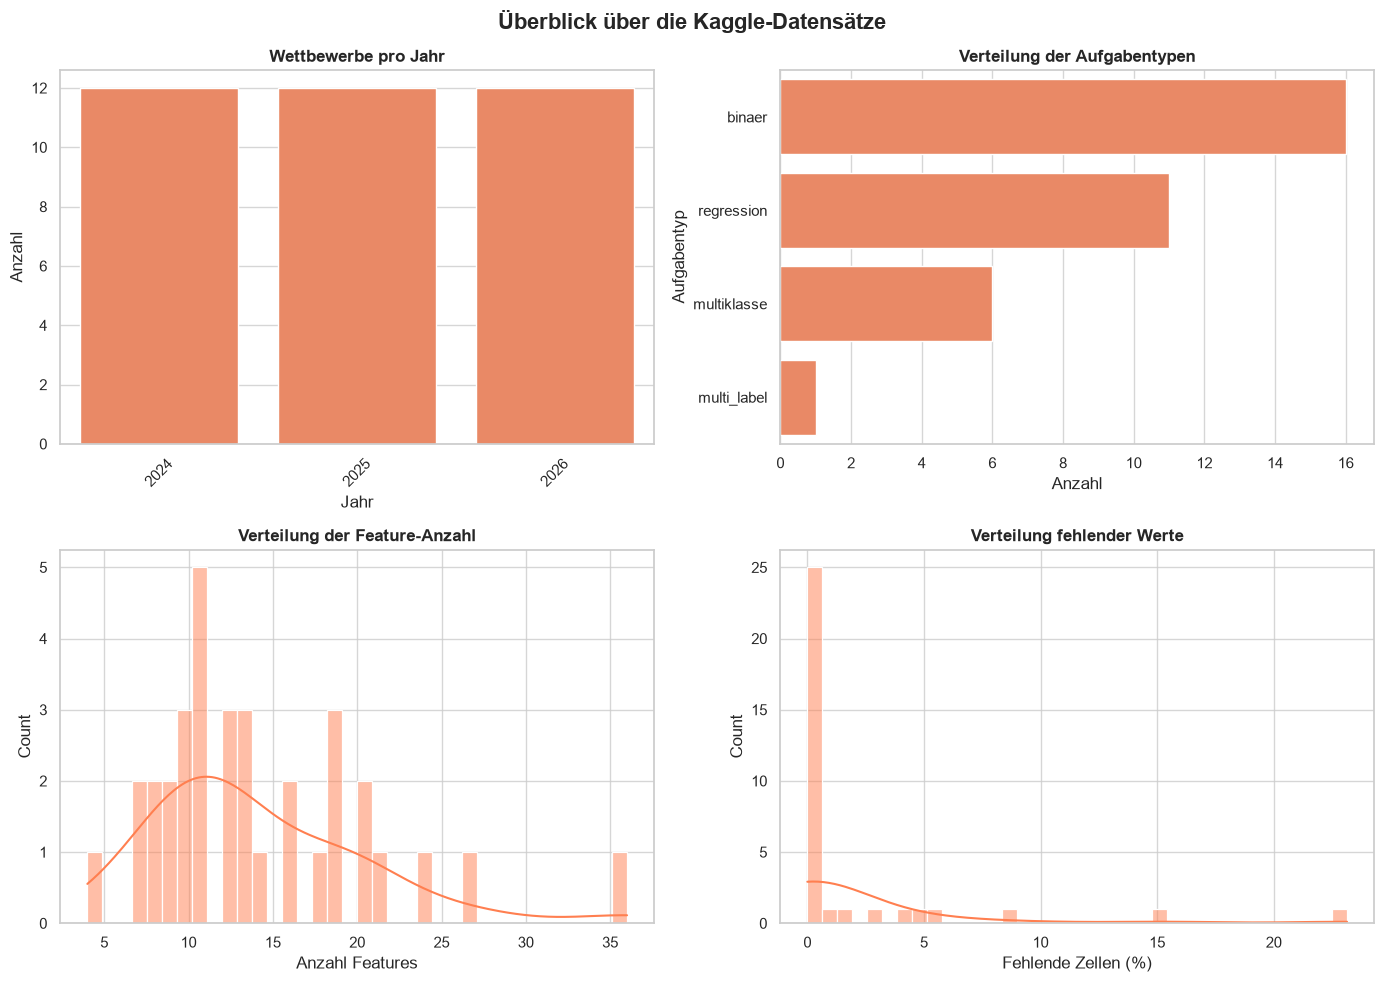

In [66]:

sns.set_theme(
    style="whitegrid",
    palette=["coral"],
    context="notebook"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "Überblick über die Kaggle-Datensätze",
    fontsize=16,
    fontweight="bold"
)

# 1. Wettbewerbe pro Jahr
sns.countplot(data=data, x="Jahr", ax=axes[0, 0])
axes[0, 0].set_title("Wettbewerbe pro Jahr")
axes[0, 0].set_xlabel("Jahr")
axes[0, 0].set_ylabel("Anzahl")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Aufgabentypen
sns.countplot(
    data=data, y="aufgabe_vermutet",
    order=data["aufgabe_vermutet"].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Verteilung der Aufgabentypen")
axes[0, 1].set_xlabel("Anzahl")
axes[0, 1].set_ylabel("Aufgabentyp")

# 3. Anzahl Features
sns.histplot(data=data, x="n_features", bins=len(data), kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Verteilung der Feature-Anzahl")
axes[1, 0].set_xlabel("Anzahl Features")

# 4. Fehlende Werte
sns.histplot(
    data=data, x="anteil_fehlend_prozent",
    bins=len(data), kde=True, ax=axes[1, 1]
)
axes[1, 1].set_title("Verteilung fehlender Werte")
axes[1, 1].set_xlabel("Fehlende Zellen (%)")


plt.tight_layout()
plt.show()


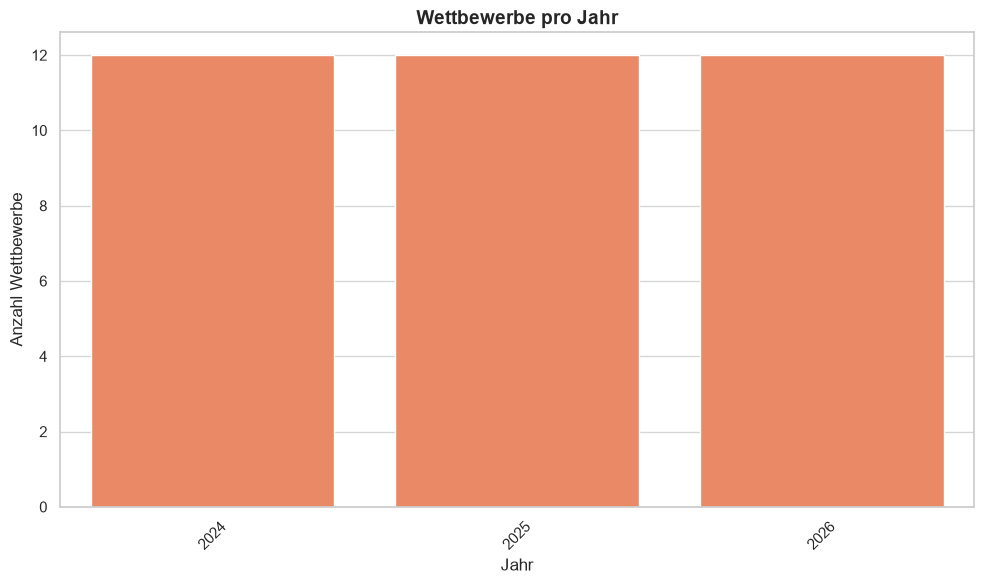

In [44]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="Jahr",
    color="coral"
)

plt.title("Wettbewerbe pro Jahr", fontsize=14, fontweight="bold")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Wettbewerbe")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

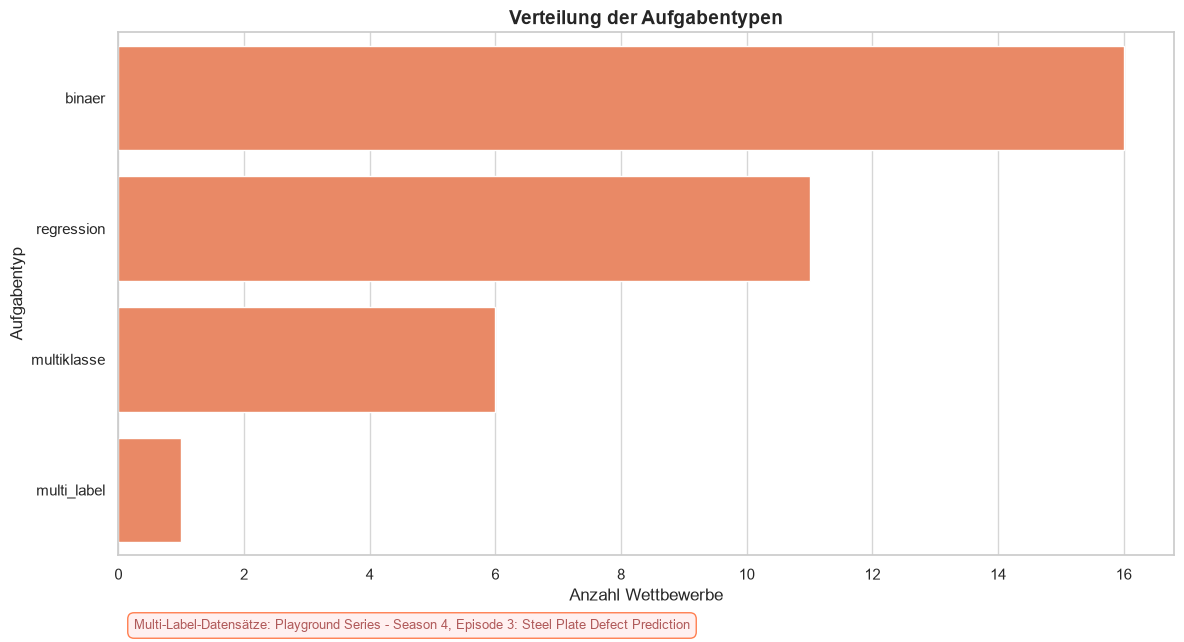

In [63]:
plt.figure(figsize=(12, 7))

ax = sns.countplot(
    data=data,
    y="aufgabe_vermutet",
    order=data["aufgabe_vermutet"].value_counts().index,
    color="coral"
)

plt.title("Verteilung der Aufgabentypen", fontsize=14, fontweight="bold")
plt.xlabel("Anzahl Wettbewerbe")
plt.ylabel("Aufgabentyp")

multi_label = data[
    data["aufgabe_vermutet"].astype(str).str.contains(
        "multi_label", case=False, na=False
    )
]

if not multi_label.empty:
    ml_text = "Multi-Label-Datensätze: " + ", ".join(
        multi_label["Titel"].astype(str)
    )

    plt.figtext(
        0.35, 0.09,
        ml_text,
        ha="center",
        fontsize=9,
        color="#B05A5A",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="#FFF0F0",
            edgecolor="coral"
        )
    )

plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

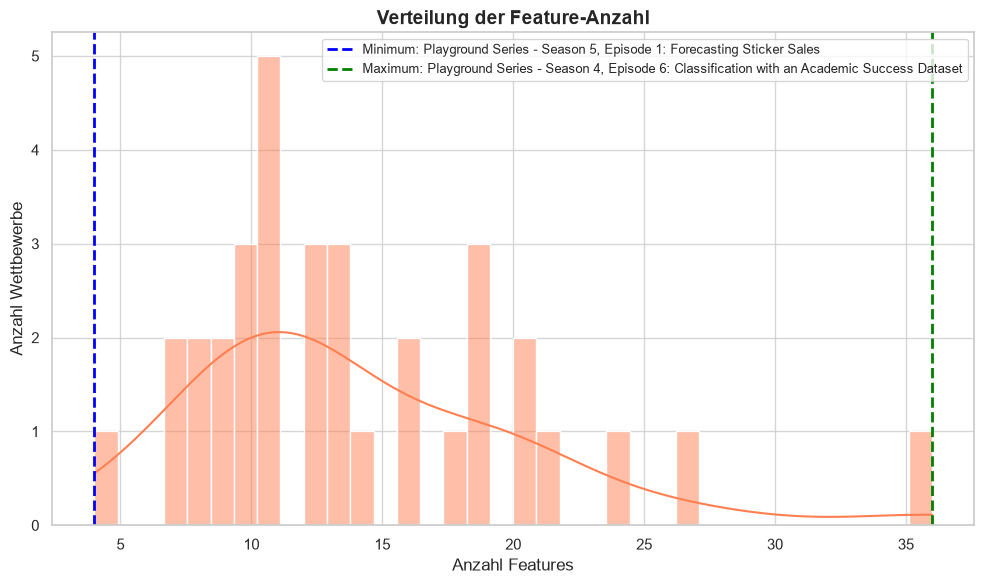

In [51]:
min_features = data.loc[data["n_features"].idxmin()]
max_features = data.loc[data["n_features"].idxmax()]

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    data=data,
    x="n_features",
    bins=len(data),
    kde=True,
    color="coral"
)

ax.axvline(
    min_features["n_features"],
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Minimum: {min_features['Titel']}"
)

ax.axvline(
    max_features["n_features"],
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Maximum: {max_features['Titel']}"
)

plt.title("Verteilung der Feature-Anzahl", fontsize=14, fontweight="bold")
plt.xlabel("Anzahl Features")
plt.ylabel("Anzahl Wettbewerbe")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

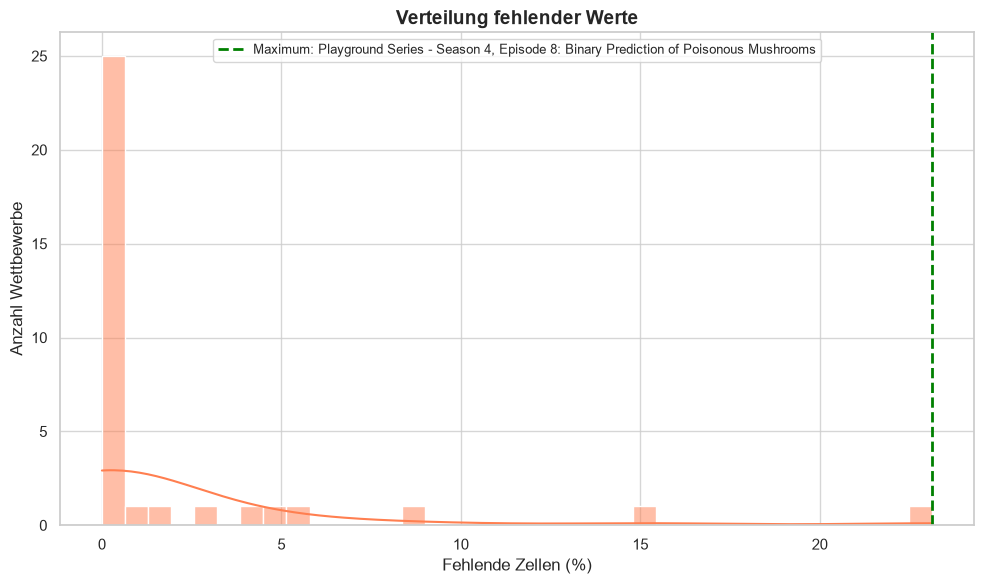

In [53]:
max_missing = data.loc[data["anteil_fehlend_prozent"].idxmax()]

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    data=data,
    x="anteil_fehlend_prozent",
    bins=len(data),
    kde=True,
    color="coral"
)

ax.axvline(
    max_missing["anteil_fehlend_prozent"],
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Maximum: {max_missing['Titel']}"
)

plt.title("Verteilung fehlender Werte", fontsize=14, fontweight="bold")
plt.xlabel("Fehlende Zellen (%)")
plt.ylabel("Anzahl Wettbewerbe")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

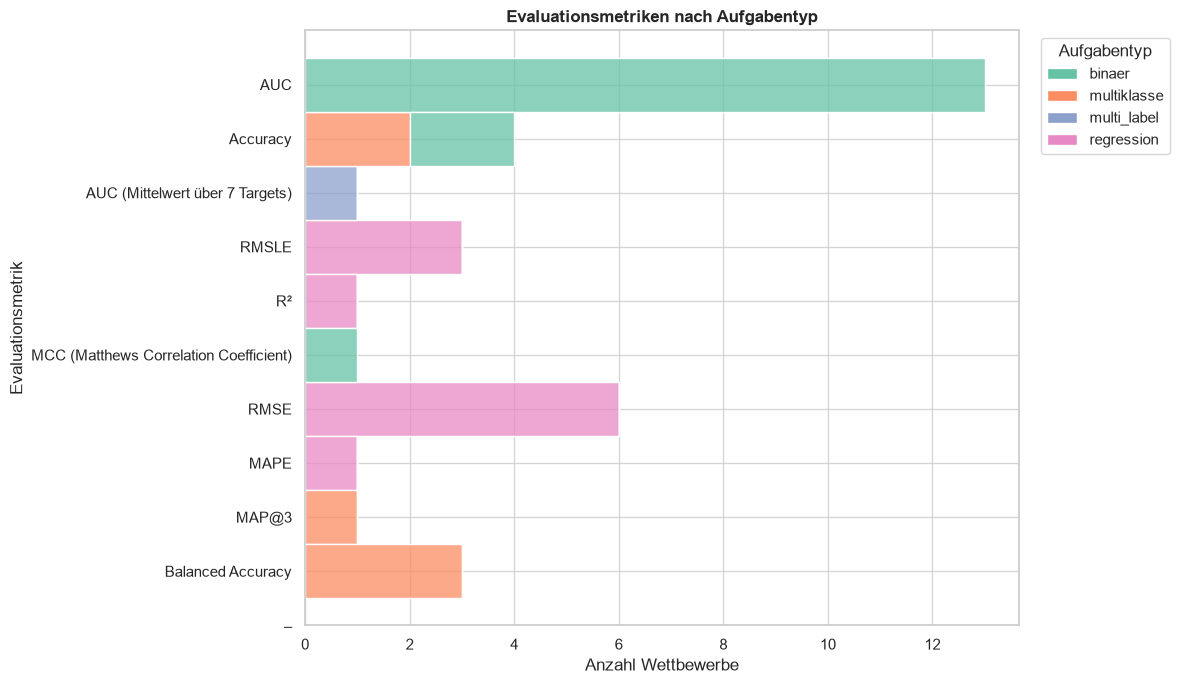

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

plt.figure(figsize=(12, 7))

# Kategorien und Farben festlegen
kategorien = data["aufgabe_vermutet"].dropna().unique()
farben = sns.color_palette("Set2", n_colors=len(kategorien))
farben_dict = dict(zip(kategorien, farben))

ax = sns.histplot(
    data=data,
    y="Metrik",
    hue="aufgabe_vermutet",
    multiple="stack",
    discrete=True,
    palette=farben_dict,
    legend=False
)

# Legende manuell erstellen
legenden_elemente = [
    Patch(facecolor=farben_dict[kategorie], label=kategorie)
    for kategorie in kategorien
]

ax.legend(
    handles=legenden_elemente,
    title="Aufgabentyp",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.title("Evaluationsmetriken nach Aufgabentyp")
plt.xlabel("Anzahl Wettbewerbe")
plt.ylabel("Evaluationsmetrik")

plt.tight_layout()
plt.show()

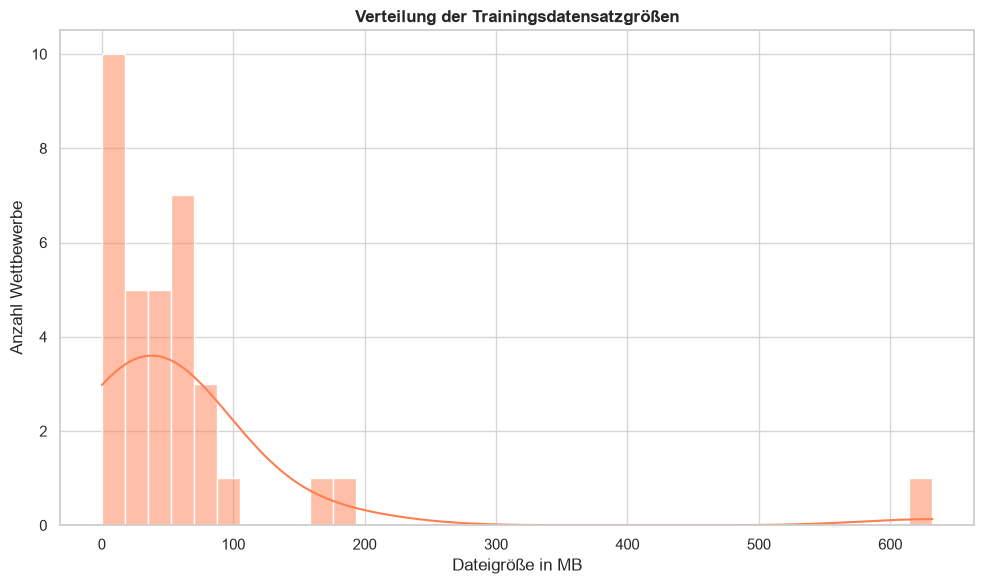

In [64]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x="train_mb",
    bins=len(data),
    kde=True,
    color="coral"
)

plt.title("Verteilung der Trainingsdatensatzgrößen")
plt.xlabel("Dateigröße in MB")
plt.ylabel("Anzahl Wettbewerbe")
plt.tight_layout()
plt.show()